# Дополнительные упражнения из учебных примеров

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "93_additional_exercises"
OUT.mkdir(exist_ok=True, parents=True)

## L1-регуляризация и PCA вручную

Сравниваю L1-регуляризацию и считаю PCA через собственные векторы ковариационной матрицы. Результат проверяю со sklearn.

,L1,accuracy,macro_f1,weight_L1,fraction_abs_below_1e-3
0,0.00000,0.91,0.91000,245.09564,0.00493
1,0.00001,0.91,0.90999,214.34969,0.21839
2,0.00010,0.91,0.91000,156.29106,0.30788
3,0.00100,0.90,0.89996,60.62475,0.53530


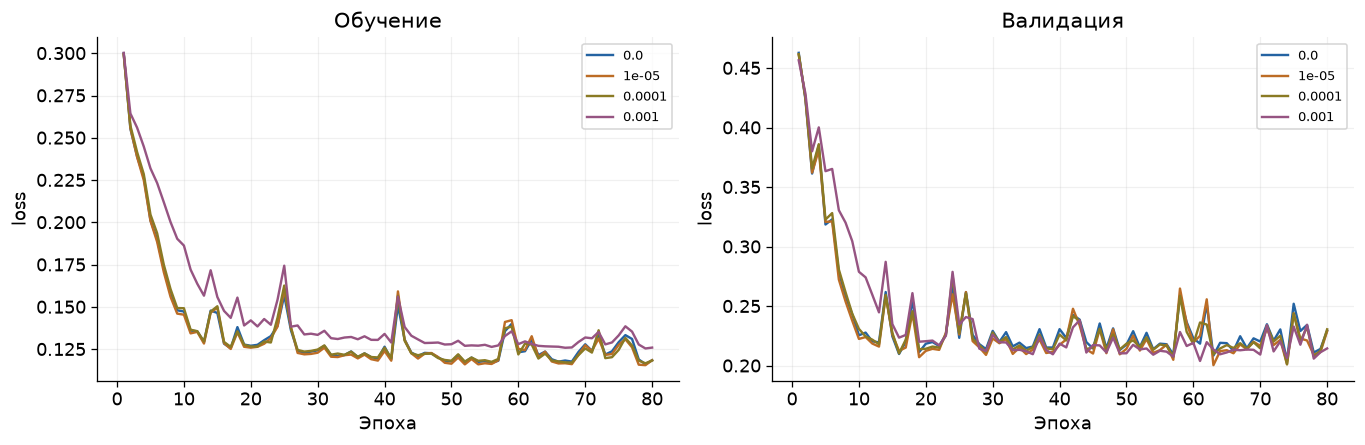

,component,eigenvalue,explained_variance_fraction
0,1,6.10754,0.72304
1,2,1.42324,0.16849
2,3,0.91623,0.10847


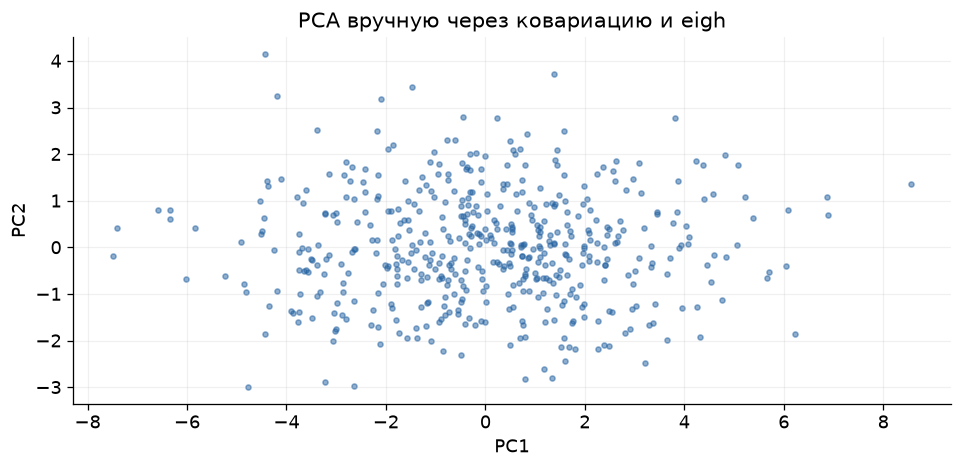

L1 приближает веса к нулю. Долю почти нулевых весов считаю с допуском 1e−3. В PCA собственные векторы ковариации задают направления, собственные значения — дисперсии. При сравнении учитываю произвольный знак векторов.

In [2]:
from additional import l1_and_pca, alex_nin, name_rnn, yolo_resolution, mask_overlap

l1_and_pca(OUT)

## AlexNet и NiN на Fashion-MNIST

Сравниваю уменьшенные варианты AlexNet, вход 28×28 и разные batch size. В NiN меняю число слоёв 1×1. Считаю параметры, умножения и суммарный размер выходов слоёв.

,model,accuracy,macro_f1,parameters,multiplications_one_image,parameter_MB_fp32,sum_layer_output_MB_fp32,seconds,batch
0,AlexNet_like_96,0.69167,0.68157,266058,13098912,1.01493,0.11881,4.40599,64
1,simplified_96,0.56250,0.53916,14802,9960064,0.05647,0.68583,7.51261,64
2,simplified_native28,0.65000,0.63203,14802,853504,0.05647,0.05860,1.12770,64
3,native28_batch16,0.70417,0.70053,14802,853504,0.05647,0.05860,1.33755,16
4,native28_batch128,0.59583,0.56272,14802,853504,0.05647,0.05860,0.95107,128


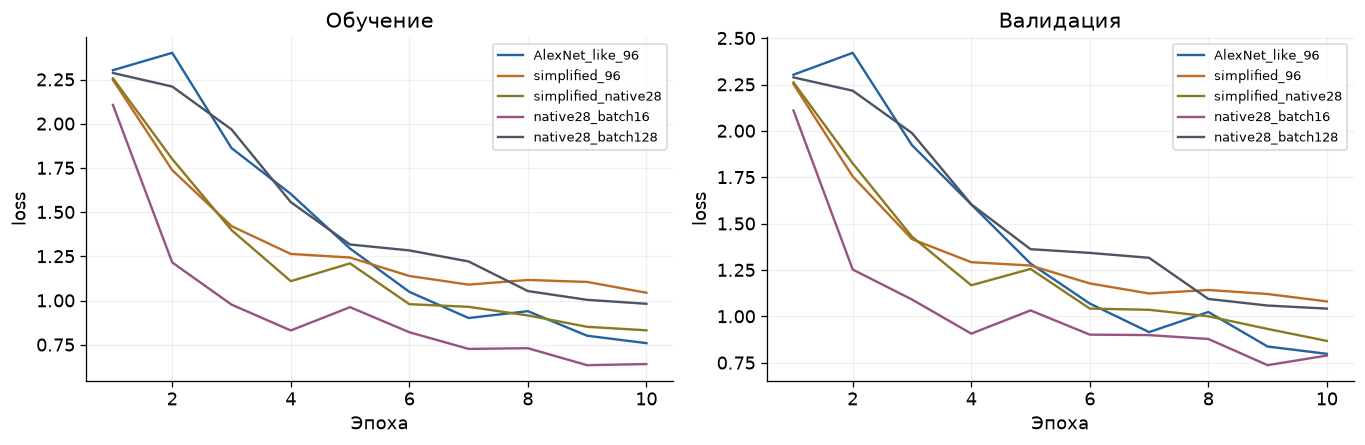

,pointwise_layers,accuracy,macro_f1,parameters,multiplications_one_image,parameter_MB_fp32,sum_layer_output_MB_fp32,seconds
0,1,0.33333,0.24252,2138,796544,0.00816,0.10318,1.45342
1,2,0.17917,0.07479,2410,997248,0.00919,0.15103,1.97750
2,3,0.17500,0.05849,2682,1197952,0.01023,0.19888,2.48765


Fashion-MNIST: 1200 объектов. AlexNet уменьшен для CPU и небольших изображений. В NiN слои 1×1 смешивают каналы. Умножения считаю для Conv2d и Linear, память — как сумму размеров выходов слоёв. Измерений GPU-памяти здесь нет.

In [3]:
alex_nin(OUT)

## Символьная RNN и другие архитектуры

Классификация фамилий из PyTorch tutorial: RNN, LSTM и GRU, матрица ошибок и примеры неверных ответов.

,kind,accuracy,macro_f1,seconds
0,RNN,0.80000,0.79961,0.18769
1,LSTM,0.81333,0.81319,0.38569
2,GRU,0.82000,0.81764,0.30063


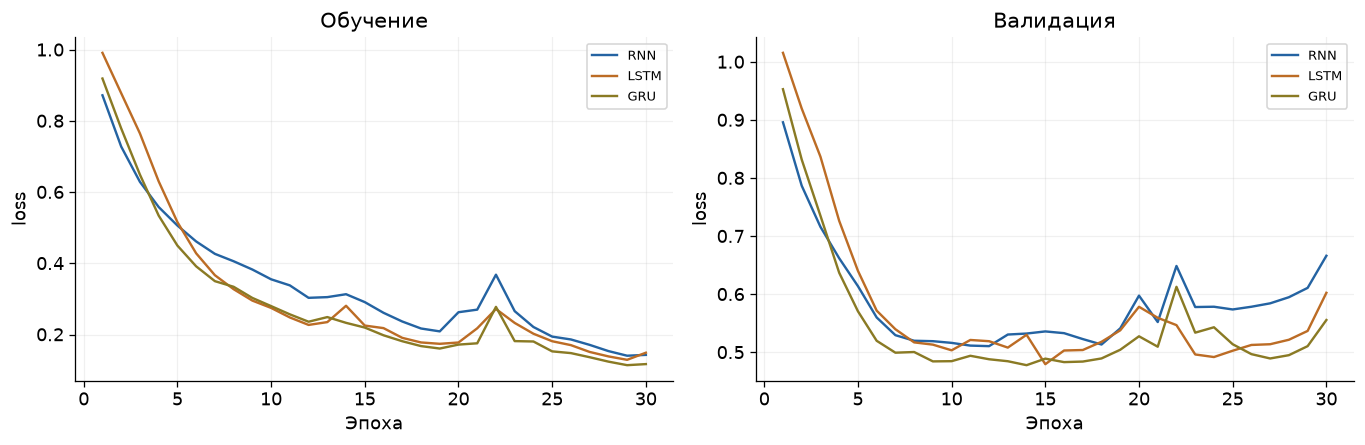

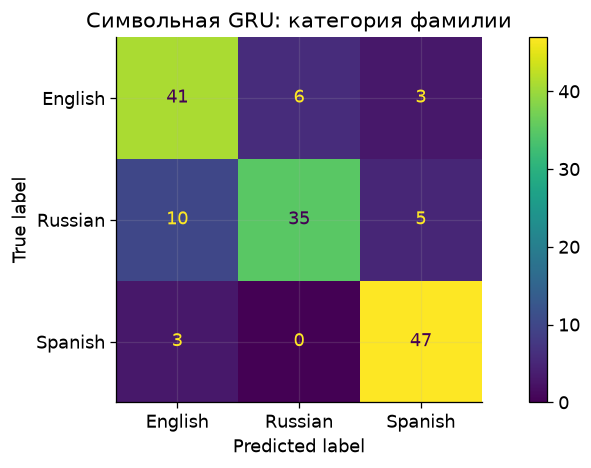

,name,true,predicted
0,aberson,Russian,Spanish
1,dikusar,Russian,English
2,rankin,English,Russian
3,havinson,Russian,English
4,alliott,English,Spanish
5,jaba,Russian,Spanish
6,leibe,Russian,English
7,gallinger,Russian,English
8,karim,English,Russian
9,salazar,Spanish,English


Данные — фамилии из PyTorch tutorial. Одна фамилия может встречаться в нескольких языковых группах. Packing исключает PAD из скрытого состояния.

In [4]:
name_rnn(OUT)

## YOLO при разных размерах входа

Пять размеров входа на одних фотографиях. Сравниваю precision, recall и время.

,size,TP,FP,FN,precision,recall,median_ms
0,192,26,1,4,0.96296,0.86667,5.99354
1,256,28,2,2,0.93333,0.93333,7.38688
2,320,29,2,1,0.93548,0.96667,9.05033
3,384,30,2,0,0.93750,1.00000,11.58942
4,448,30,3,0,0.90909,1.00000,13.03658


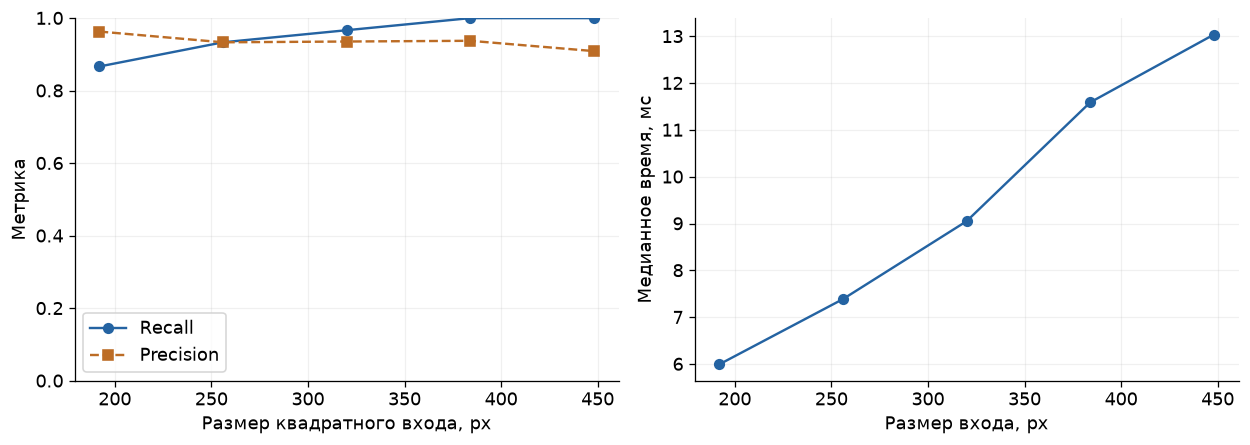

YOLO11n с весами COCO. Вход BGR, rect=False, person=0 переведён в person=1. Первый проход пропускаю при измерении времени. Для всех размеров использую одни десять фотографий и порог 0.4.

In [5]:
yolo_resolution(OUT)

## Mask R-CNN: перекрытие объектов

Четыре составных изображения с разным перекрытием людей. Считаю найденные объекты и Dice объединённой маски.

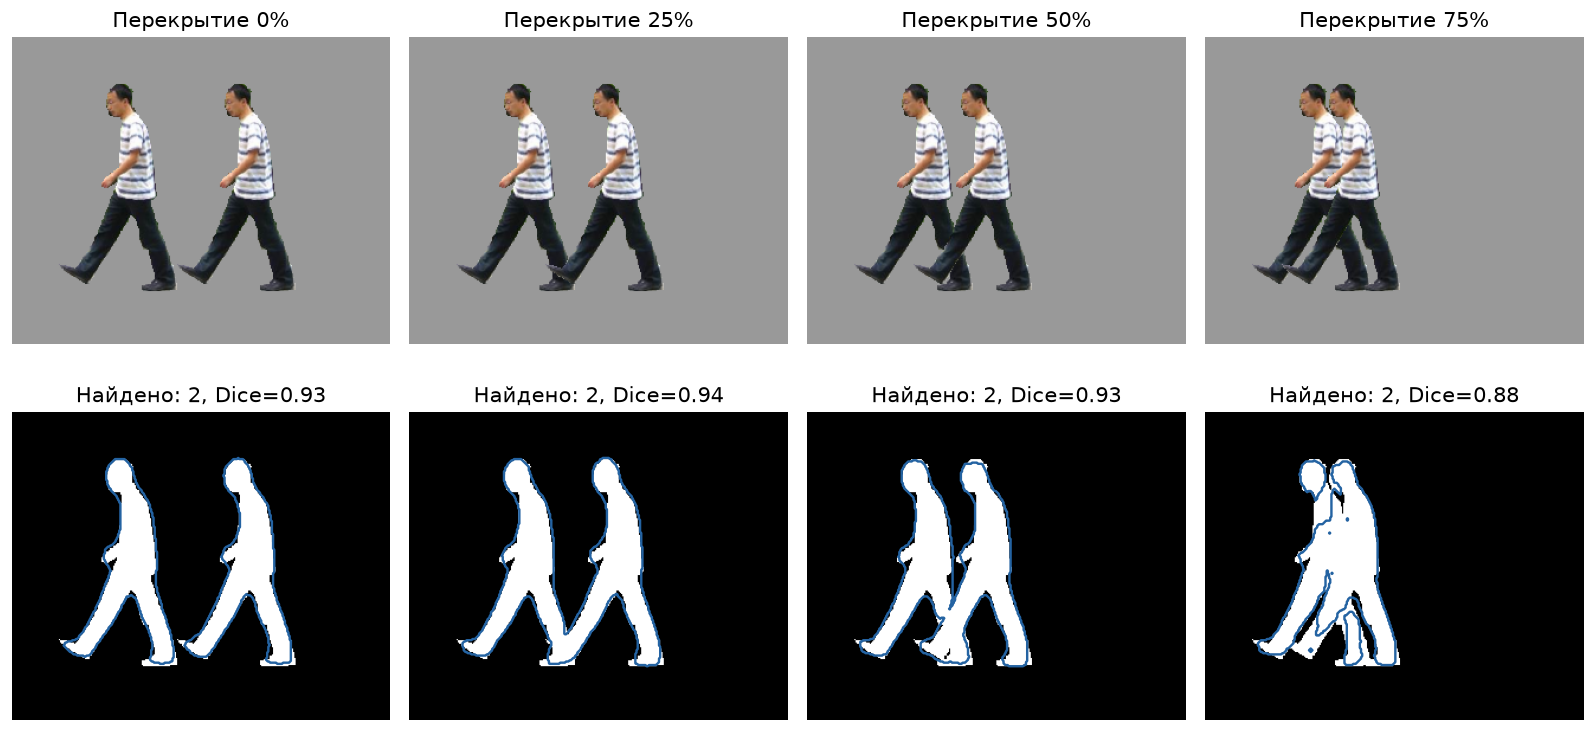

,horizontal_overlap_fraction,detected_people,union_Dice,union_IoU
0,0.00,2,0.93259,0.87370
1,0.25,2,0.93539,0.87862
2,0.50,2,0.93079,0.87054
3,0.75,2,0.87605,0.77943


Фигуру вырезаю по исходной маске и дважды размещаю на одном фоне. Белым показана объединённая разметка, голубым — граница Mask R-CNN. Dice объединённой маски может быть высоким, даже если два человека найдены как один объект.

In [6]:
mask_overlap(OUT)